In [1]:
# Cell 1: Set paths and processing parameters.
from pathlib import Path
import sys

# Run from coverage/ or its parent project directory.
COVERAGE_DIR = Path.cwd().resolve()
if not (COVERAGE_DIR / "coverage_refactored.ipynb").is_file():
    COVERAGE_DIR = COVERAGE_DIR / "coverage"
if not (COVERAGE_DIR / "coverage_refactored.ipynb").is_file():
    raise FileNotFoundError("Start Jupyter from coverage/ or its parent directory.")
PROJECT_ROOT = COVERAGE_DIR.parent
sys.path.insert(0, str(COVERAGE_DIR))
RUN_DIR = COVERAGE_DIR / "output" / "analysis_001"
CONFIG = {
    "data_dir": "data/mag2000",
    "target_plates": {'new': ['pl01', 'pl02', 'pl04', 'pl05', 'pl06', 'pl07', 'pl08', 'pl09', 'pl10', 'pl11', 'pl12', 'pl13', 'pl14', 'pl15', 'pl16', 'pl17', 'pl18', 'pl19'], 'old': ['pl01', 'pl02', 'pl04', 'pl07', 'pl08', 'pl09', 'pl11', 'pl13', 'pl14', 'pl15', 'pl17', 'pl18', 'pl19', 'pl21', 'pl22', 'pl23', 'pl24', 'pl27']},
    "images_per_plate": 8,  # All available images; new/pl13 contains seven.
    "crop": {"top": 60, "bottom": 100, "left": 60, "right": 100},
    "max_sample_pixels": 10000, "predict_chunk_size": 200000, "random_state": 0,
}
DATA_DIR = PROJECT_ROOT / CONFIG["data_dir"]
print(f"Project: {PROJECT_ROOT}\nCoverage images: {DATA_DIR}\nRun: {RUN_DIR}")
print(f"Input directory exists: {DATA_DIR.is_dir()}")

PHOTON_YIELD_PATH = PROJECT_ROOT / "implement" / "data" / "tables" / "photon_yield.csv"


Project: /home/kmanabe2403/dune
Coverage images: /home/kmanabe2403/dune/data/mag2000
Run: /home/kmanabe2403/dune/coverage/output/analysis_001
Input directory exists: True


In [2]:
# Cell 2: Select images and save the manifest and settings (original Cell 2).
# Use a new RUN_DIR when changing input images or processing parameters.
from coverage_pipeline import prepare_run

prepare_run(PROJECT_ROOT, RUN_DIR, CONFIG)

Selected 287 images. Metadata: /home/kmanabe2403/dune/coverage/output/analysis_001/metadata


In [3]:
# Cell 3: Crop and save each image separately (original Cell 3).
from coverage_pipeline import crop_images

crop_images(PROJECT_ROOT, RUN_DIR)

Saved 287 cropped images: /home/kmanabe2403/dune/coverage/output/analysis_001/images


In [4]:
# Cell 4: Run pixel GMM with 2, 4, and hierarchical 2 -> 2 clusters (original Cell 4).
# Save label maps and area ratios per image. Rerunning rebuilds the result CSV.
from coverage_pipeline import run_gmm

GMM_AREA_PATH = run_gmm(RUN_DIR)

GMM complete: 0 new/pl01/20260806_130816
GMM complete: 1 new/pl01/20260806_130916
GMM complete: 2 new/pl01/20260806_131002
GMM complete: 3 new/pl01/20260806_131042
GMM complete: 4 new/pl01/20260806_131117
GMM complete: 5 new/pl01/20260806_131150
GMM complete: 6 new/pl01/20260806_131234
GMM complete: 7 new/pl01/20260806_131313
GMM complete: 8 new/pl02/20260806_131651
GMM complete: 9 new/pl02/20260806_131737
GMM complete: 10 new/pl02/20260806_131830
GMM complete: 11 new/pl02/20260806_131903
GMM complete: 12 new/pl02/20260806_132005
GMM complete: 13 new/pl02/20260806_132041
GMM complete: 14 new/pl02/20260806_132114
GMM complete: 15 new/pl02/20260806_132146
GMM complete: 16 new/pl04/20260806_132545
GMM complete: 17 new/pl04/20260806_132627
GMM complete: 18 new/pl04/20260806_132702
GMM complete: 19 new/pl04/20260806_132735
GMM complete: 20 new/pl04/20260806_132812
GMM complete: 21 new/pl04/20260806_132848
GMM complete: 22 new/pl04/20260806_132929
GMM complete: 23 new/pl04/20260806_133007
GM

Review figures saved: 10/287
Review figures saved: 20/287
Review figures saved: 30/287
Review figures saved: 40/287
Review figures saved: 50/287
Review figures saved: 60/287
Review figures saved: 70/287
Review figures saved: 80/287
Review figures saved: 90/287
Review figures saved: 100/287
Review figures saved: 110/287
Review figures saved: 120/287
Review figures saved: 130/287
Review figures saved: 140/287
Review figures saved: 150/287
Review figures saved: 160/287
Review figures saved: 170/287
Review figures saved: 180/287
Review figures saved: 190/287
Review figures saved: 200/287
Review figures saved: 210/287
Review figures saved: 220/287
Review figures saved: 230/287
Review figures saved: 240/287
Review figures saved: 250/287
Review figures saved: 260/287
Review figures saved: 270/287
Review figures saved: 280/287
Review figures saved: 287/287


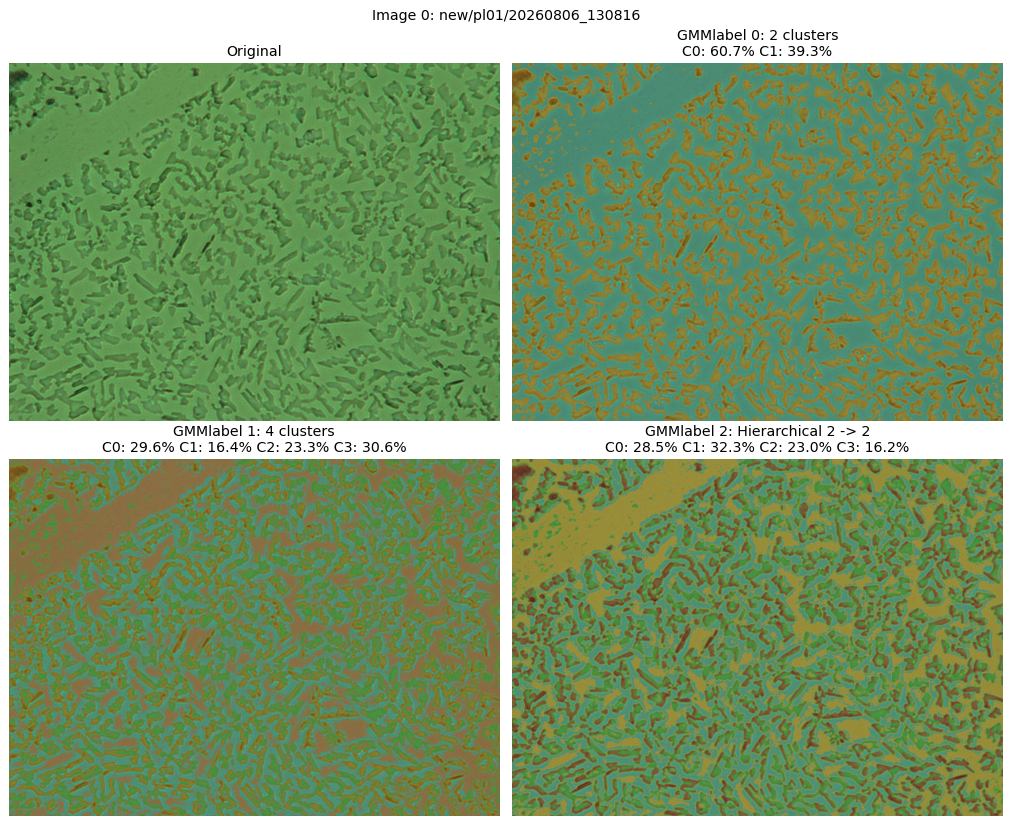

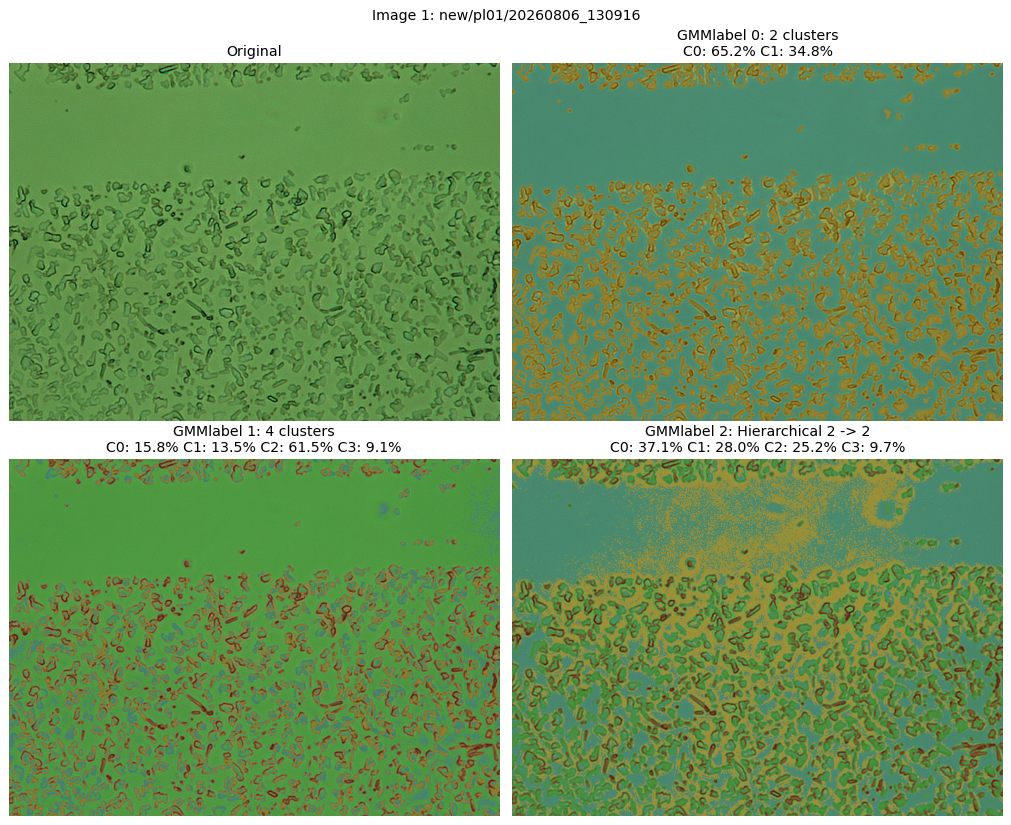

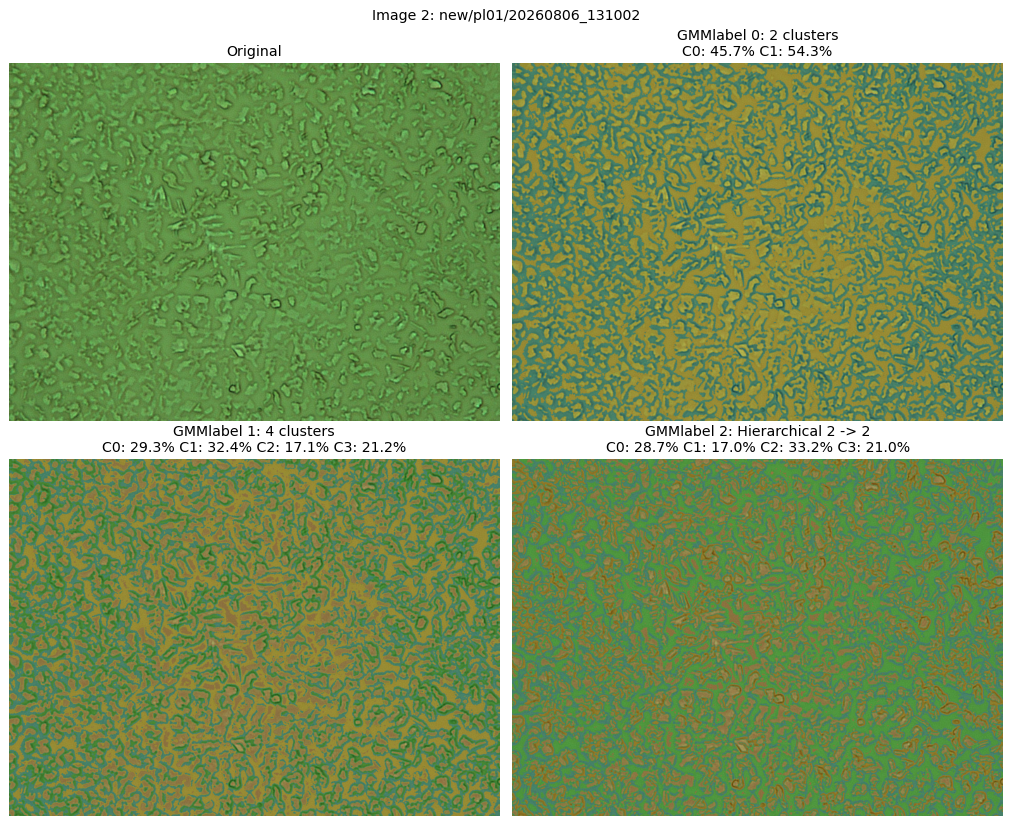

In [5]:
# Cell 5: Inspect and save the three GMM comparisons (original Cell 4).
from coverage_analysis import show_gmm

show_gmm(RUN_DIR, image_ids=None, max_display=3)  # Save all comparison PNGs; display three examples.

In [6]:
# Cell 6: Prepare empty-area settings and import matching existing selections.
# Match by group, plate and image name; preserve current image IDs and local edits.
from coverage_pipeline import prepare_settings, import_settings

GMM_SETTINGS_PATH = prepare_settings(RUN_DIR)
EXISTING_SETTINGS_PATH = PROJECT_ROOT / "implement" / "data" / "tables" / "coverage_settings.csv"
GMM_SETTINGS_PATH = import_settings(RUN_DIR, EXISTING_SETTINGS_PATH)
# Nameless manual rows are kept separately in review/plate_manual_settings.csv.

Edit cluster (comma-separated IDs) or fluction (manual empty fraction, 0–1): /home/kmanabe2403/dune/coverage/output/analysis_001/review/gmm_settings.csv
GMMlabel: 0 = two clusters; 1 = four clusters; 2 = hierarchical 2 -> 2. Existing settings are preserved.
source_has_no_selection    131
imported                   100
no_matching_image           56
Plate-level manual values retained separately: 7


In [7]:
# Cell 7: Calculate image coverage and plate summaries (original Cell 6).
# Skip unselected images. Summarize plates with at least two selected images.
import pandas as pd
from IPython.display import display
from coverage_analysis import calculate_coverage

PLATE_COVERAGE_PATH = calculate_coverage(RUN_DIR)
display(pd.read_csv(RUN_DIR / "coverage" / "image_coverage.csv"))
display(pd.read_csv(PLATE_COVERAGE_PATH))

Coverage: 100 images; 25 plate/source groups; 187 unselected images.
Plate summaries require at least two selected images per plate and source.


,image_id,group,plate,name,gmm_label,cluster,fluction,empty_ratio,coverage,source
0,0,new,pl01,20260806_130816,0.0,0,NaN,0.607135,0.392865,cluster
1,1,new,pl01,20260806_130916,0.0,0,NaN,0.651748,0.348252,cluster
2,2,new,pl01,20260806_131002,2.0,"0,2",NaN,0.619377,0.380623,cluster
3,4,new,pl01,20260806_131117,0.0,1,NaN,0.572105,0.427895,cluster
4,6,new,pl01,20260806_131234,0.0,1,NaN,0.567040,0.432960,cluster
...,...,...,...,...,...,...,...,...,...,...
95,269,old,pl23,20260806_145557,2.0,1,NaN,0.238889,0.761111,cluster
96,270,old,pl23,20260806_145648,0.0,0,NaN,0.595026,0.404974,cluster
97,281,old,pl27,20260806_142743,2.0,1,NaN,0.289191,0.710809,cluster
98,282,old,pl27,20260806_142830,2.0,3,NaN,0.334160,0.665840,cluster


,group,plate,source,coverage,coverage_min,coverage_max,n_images
0,new,pl01,cluster,0.404164,0.396519,0.415346,6
1,new,pl02,cluster,0.667312,0.650345,0.691726,7
2,new,pl04,cluster,0.568391,0.557995,0.590941,8
3,new,pl05,cluster,0.470541,0.456948,0.497789,6
4,new,pl06,cluster,0.432286,0.413071,0.443654,5
5,new,pl08,cluster,0.674715,0.670902,0.677038,5
6,new,pl09,cluster,0.518991,0.473248,0.627562,5
7,new,pl10,cluster,0.651562,0.643006,0.665073,6
8,new,pl11,cluster,0.541179,0.511746,0.566381,6
9,new,pl13,cluster,0.484742,0.454386,0.513791,5


Photon comparison: 18 plates; 0 missing photon yields.
Linear fit: y = 120.3202x + -17.3675; R² = 0.3499


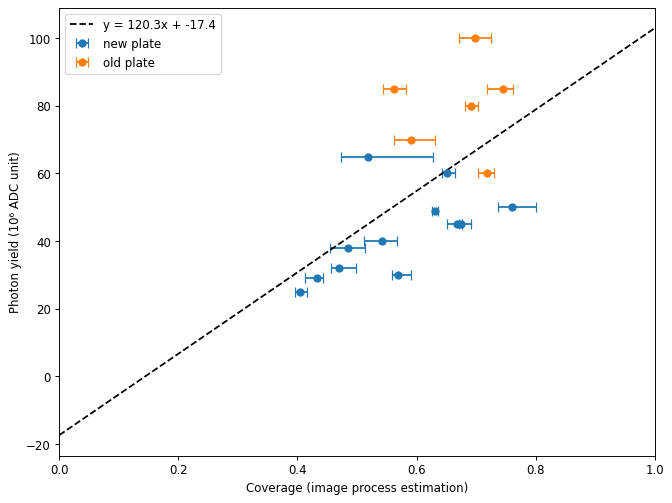

In [8]:
# Cell 8: Compare cluster-based plate coverage with photon yield (original Cell 6).
# Error bars: leave-one-image-out mean ranges, not confidence intervals.
from coverage_analysis import plot_photon_yield

plot_photon_yield(RUN_DIR, PHOTON_YIELD_PATH)